# Marmousi: DiffPIR


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from IPython.display import display
from diffusers import UNet2DConditionModel, MultiControlNetModel

from myddim_schedule import DDIMScheduler
from utils import wavelet_forward, calc_metrics
from inference_utils import get_impedance_cmap
from paper_plotting import section_figure_size, paper_section, paper_colorbar as add_colorbar
from inversion_utils import wavelet_fitting
from utils import gaussian_kernel, prepare_background
from contextlib import nullcontext


## 1. Device, Model, and Schedulers


In [2]:
ROOT = Path.cwd().resolve()
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
path = ROOT / "weights" / "checkpoint-22608"

torch.set_num_threads(8)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cuda.matmul.allow_tf32 = False

unet = UNet2DConditionModel.from_pretrained(path, subfolder="unet").to(device)
controlnet = MultiControlNetModel.from_pretrained(str(path / "controlnet/controlnet")).to(device)
unet.eval().requires_grad_(False)
controlnet.eval().requires_grad_(False)
scheduler = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
scheduler2 = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
if scheduler.config.prediction_type != "v_prediction" or scheduler.config.num_train_timesteps != 1500:
    raise ValueError("The checkpoint prediction type or number of training timesteps does not match the settings used in the paper.")
print("Device:", device)

# Data gradients pass through the frozen networks; retain the original gradient-checkpointing switch.
unet.enable_gradient_checkpointing()
controlnet.enable_gradient_checkpointing()


The config attributes {'add_attention': True, 'attn_norm_num_groups': None, 'downsample_type': 'conv', 'num_train_timesteps': None, 'upsample_type': 'conv'} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Device: cuda:3


## 2. Select Input Data


In [3]:
data_dir = ROOT / "data" / "marmousi" / "marmousi_2300x730"
output_dir = ROOT / "results" / "marmousi_diffpir" / data_dir.name
output_dir.mkdir(parents=True, exist_ok=True)

metadata = json.loads((data_dir / "section_metadata.json").read_text(encoding="utf-8"))
print("Input:", data_dir)
print("Output:", output_dir)


Input: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/data/marmousi/marmousi_2300x730
Output: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/results/marmousi_diffpir/marmousi_2300x730


## 3. Impedance Section and Observed Seismic Data


In [4]:
imp_min, imp_max = float(metadata["imp_min"]), float(metadata["imp_max"])
raw_image_denorm = torch.from_numpy(
    np.load(data_dir / "clean_section.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
raw_image = (raw_image_denorm - imp_min) / (imp_max - imp_min)
seis_slice = torch.from_numpy(
    np.load(data_dir / "seis_slice.npy", allow_pickle=False)).float()[None, None].to(device)
if raw_image.ndim != 3 or tuple(raw_image.shape[-2:]) != tuple(seis_slice.shape[-2:]):
    raise ValueError("Impedance and seismic data must be 2D sections with matching dimensions.")
seis_min, seis_max = seis_slice.min(), seis_slice.max()
seis_amplitude = float(seis_slice.abs().max())
if seis_amplitude <= 0:
    raise ValueError("The observed seismic amplitudes must not all be zero.")
seis = (seis_slice / seis_amplitude * 0.5 + 0.5).squeeze(0)

f0 = float(metadata.get("f0", 80.0))
dt = float(metadata.get("dt", metadata.get("seismic_generation", {}).get("dt", 0.0005)))
cmap = get_impedance_cmap("marmousi")
cmap2 = plt.get_cmap("seismic")
plot_min, plot_max = (3000.0, 11000.0)
aspect = 1
print("Shape:", tuple(raw_image.shape[-2:]), "| f0:", f0, "| dt:", dt)

# The following settings only format the article figures; they do not affect normalization, forward modeling, or metrics.
plot_options = dict(dataset="marmousi", wells=metadata.get("well_starts", ()),
                    well_width=int(metadata.get("well_width", 3)), dt=dt)


Shape: (2300, 730) | f0: 80.0 | dt: 0.0005


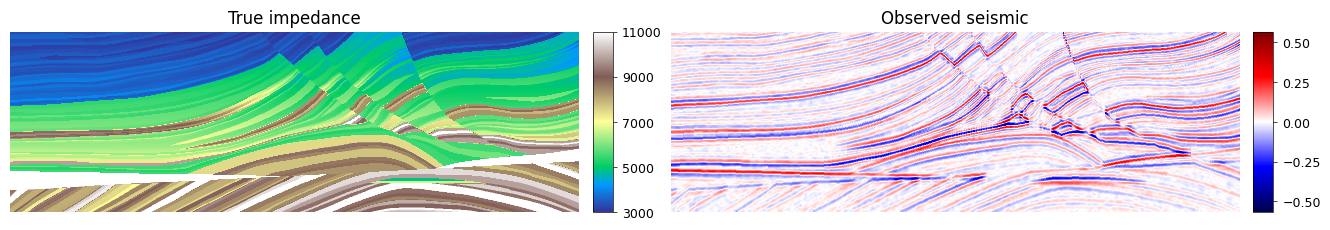

In [5]:
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis_slice[0, 0].cpu().T, cmap=cmap2, vmin=-seis_amplitude,
           vmax=seis_amplitude, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 4. Well Logs and Masks


Well starts: [107, 270, 511, 1137, 1854, 2117]


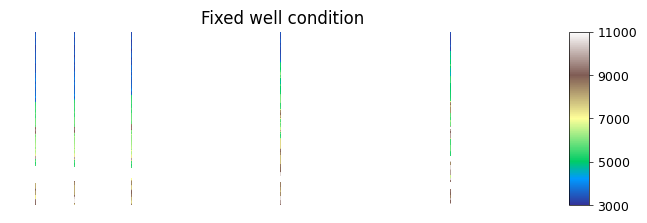

In [6]:
data_well_slice = torch.from_numpy(
    np.load(data_dir / "well_image.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
mask_well_slice = torch.from_numpy(
    np.load(data_dir / "well_mask.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if data_well_slice.shape != raw_image.shape or mask_well_slice.shape != raw_image.shape:
    raise ValueError("Well logs, masks, and impedance must have matching dimensions.")
if mask_well_slice.sum() <= 0:
    raise ValueError("Wavelet estimation requires at least one valid well-log segment.")
if (data_well_slice * (1 - mask_well_slice)).any():
    raise ValueError("Well-log conditions must be zero outside the mask.")
well_images = data_well_slice.unsqueeze(0)
mask = mask_well_slice.unsqueeze(0)

columns = torch.where(mask[0, 0].any(dim=-1))[0].cpu().numpy()
dot = columns[np.r_[True, np.diff(columns) > 1]].tolist()
print("Well starts:", dot)
well_images_denorm = (well_images * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
# Well overlays come from the actual input logs and masks and are used only for display.
plot_options.update(wells=dot,
                    well_values=well_images_denorm[0, 0].detach().cpu().numpy(),
                    well_mask=mask[0, 0].detach().cpu().numpy())
shown_wells = np.ma.masked_where(mask[0, 0].cpu().numpy().T == 0,
                                well_images_denorm[0, 0].cpu().numpy().T)
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], cols=1, dataset=plot_options["dataset"]))
plt.imshow(shown_wells, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("Fixed well condition")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 5. Initial Low-Frequency Model


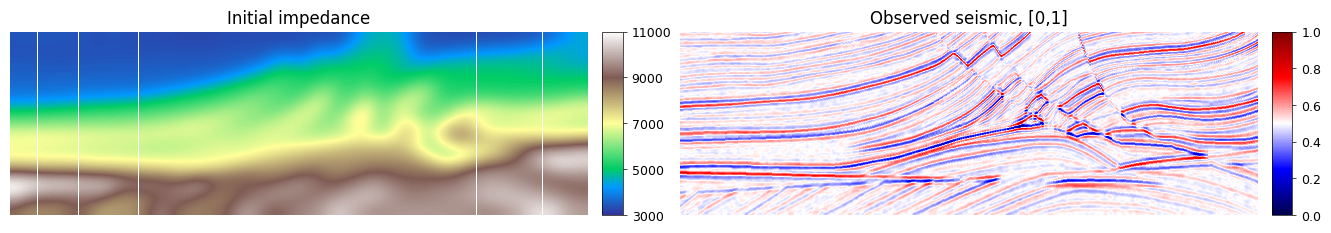

In [7]:
ks = int(metadata["initial_model_kernel"])
smoothed = torch.from_numpy(
    np.load(data_dir / "initial_model.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if smoothed.shape != raw_image.shape:
    raise ValueError("The initial model and impedance must have matching dimensions.")
if metadata.get("initial_model_scale") != "normalized_0_1":
    smoothed = (smoothed - imp_min) / (imp_max - imp_min)
smoothed_denorm = smoothed * (imp_max - imp_min) + imp_min

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(smoothed_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Initial impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis[0].cpu().T, cmap=cmap2, vmin=0, vmax=1, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic, [0,1]")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 6. Normalization, Background Operator, and Evaluation Range


In [8]:
image_shape = (1, 1, *raw_image.shape[-2:])
# The comparison experiments divide observations by their maximum absolute amplitude without an extra round trip through [0,1].
smoothed_norm = smoothed.unsqueeze(0) * 2 - 1
clean_images = ((raw_image - 0.5) / 0.5).unsqueeze(0)
cond_image = seis_slice / seis_amplitude
cond_image_denoise = cond_image
well_image2 = well_images.to(device)
f0_ = torch.tensor([f0])
dt_ = torch.tensor([dt])
print("Image shape:", image_shape, "| Normalized seismic:", tuple(cond_image.shape))

# Prepare the physical conditions explicitly, preserving the original float32 conversions and normalization order.
physics_metadata = json.loads((data_dir / "section_metadata.json").read_text())
imp_range = imp_max - imp_min
metric_data_range = imp_range  # Keep the original SSIM range for framework comparisons; do not substitute the true-model range for Marmousi.
data_shape = tuple(physics_metadata.get("target_shape", [512, 512]))
forward_window = tuple(physics_metadata.get("forward_window", [512, 16]))
background_kernel_size = int(physics_metadata.get("initial_model_kernel", 201))
fixed_arrays = {name: np.load(data_dir / (name + ".npy")) for name in
                ("clean_section", "initial_model", "seis_slice", "well_image",
                 "well_mask", "estimated_wavelet_mat")}
for name, array in fixed_arrays.items():
    if not np.isfinite(array).all():
        raise ValueError("Nonfinite fixed input: " + name)
if any(fixed_arrays[name].shape != data_shape for name in
       ("clean_section", "initial_model", "seis_slice", "well_image", "well_mask")):
    raise ValueError("Unexpected input shape")
if not (imp_min - 1e-3 <= fixed_arrays["clean_section"].min() <= imp_max):
    raise ValueError("Truth scale differs from saved metadata")
if not (imp_min <= fixed_arrays["clean_section"].max() <= imp_max + 1e-3):
    raise ValueError("Truth scale differs from saved metadata")
truth_image = torch.from_numpy(fixed_arrays["clean_section"].copy()).float()
initial_image = torch.from_numpy(fixed_arrays["initial_model"].copy()).float().to(device)[None, None]
if physics_metadata.get("initial_model_scale") == "normalized_0_1":
    initial_image = initial_image * 2 - 1
else:
    initial_image = (initial_image - imp_min) / imp_range * 2 - 1
observed_image = torch.from_numpy(fixed_arrays["seis_slice"].copy()).float().to(device)[None, None]
seismic_amplitude = float(np.max(np.abs(fixed_arrays["seis_slice"])))
amplitude_tensor = torch.tensor(seismic_amplitude, dtype=torch.float32)
seismic_condition = (observed_image / seismic_amplitude).detach()
well_condition = torch.from_numpy(fixed_arrays["well_image"].copy()).float().to(device)[None, None]
background_kernel = torch.from_numpy(
    gaussian_kernel(background_kernel_size, background_kernel_size / 7)).float().to(device)
kernel_data = dict(kernel=background_kernel[None, None], shape=data_shape)
# Select conv2d/fft in cell 24 and construct background_filter in cell 26 after its parameters are defined.


Image shape: (1, 1, 2300, 730) | Normalized seismic: (1, 1, 2300, 730)


## 7. Saved Wavelet and Optional Re-estimation


In [9]:
reestimate_wavelet = False
window = (seis.shape[-2], max(1, seis.shape[-1] // 32))
int_size = (seis.shape[-2], 8)
wavelet_iterations = 80
wavelet_lr = 0.02
wavelet_amplitude_scale = 1.0
wavelet_scale = {
    "seismic": {"match": 0, "tv_x": 0, "tv_z": 0, "tv_t": 0, "sidelobe_loss": 0},
    "well": {"match": 10, "tv_x": 0, "tv_z": 500, "tv_t": 0, "sidelobe_loss": 0},
}

if reestimate_wavelet:
    wavelet_mat, norm_dic, norm_dic_seis, seis_pred_ori_return = wavelet_fitting(
        f0_[0:1], dt_[0:1], 10 / f0_[0:1], torch.tensor([1]),
        torch.ones_like(raw_image).unsqueeze(0), cond_image,
        data_well_slice.unsqueeze(0), wavelet_iterations,
        seis_min, seis_max, imp_min, imp_max,
        int_size=int_size, mask=mask, mode="ricker", method="opt", optimizer="Adam",
        lr=wavelet_lr, window=window, scale=wavelet_scale, amplitude_scale=wavelet_amplitude_scale)
else:
    wavelet_mat = torch.from_numpy(
        np.load(data_dir / "estimated_wavelet_mat.npy", allow_pickle=False)).float().to(device)
    norm_dic = {"match": []}
window_new = int_size
np.save(output_dir / "estimated_wavelet_mat.npy", wavelet_mat.cpu().numpy())
print("Wavelet shape:", tuple(wavelet_mat.shape))
print("Wavelet source:", "Re-estimated in this notebook" if reestimate_wavelet else "Fixed paper estimate")


Wavelet shape: (1, 92, 999)
Wavelet source: Fixed paper estimate


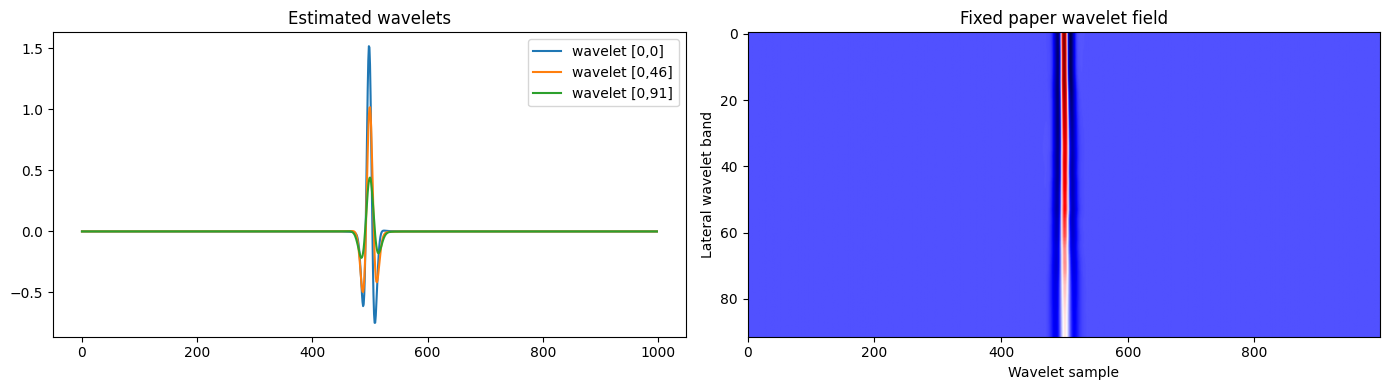

In [10]:
plt.figure(figsize=(14, 4))
plt.subplot(121)
for j in sorted(set([0, wavelet_mat.shape[1] // 2, wavelet_mat.shape[1] - 1])):
    plt.plot(wavelet_mat[0, j].detach().cpu(), label=f"wavelet [0,{j}]")
plt.title("Estimated wavelets")
plt.legend()
plt.subplot(122)
if reestimate_wavelet:
    plt.plot(norm_dic["match"], label="Well match")
    plt.title("Wavelet fitting")
    plt.legend()
else:
    plt.imshow(wavelet_mat[0].detach().cpu(), aspect="auto", cmap="seismic")
    plt.title("Fixed paper wavelet field")
    plt.xlabel("Wavelet sample")
    plt.ylabel("Lateral wavelet band")
plt.tight_layout()
plt.show()


## 8. Forward Modeling at Well Locations


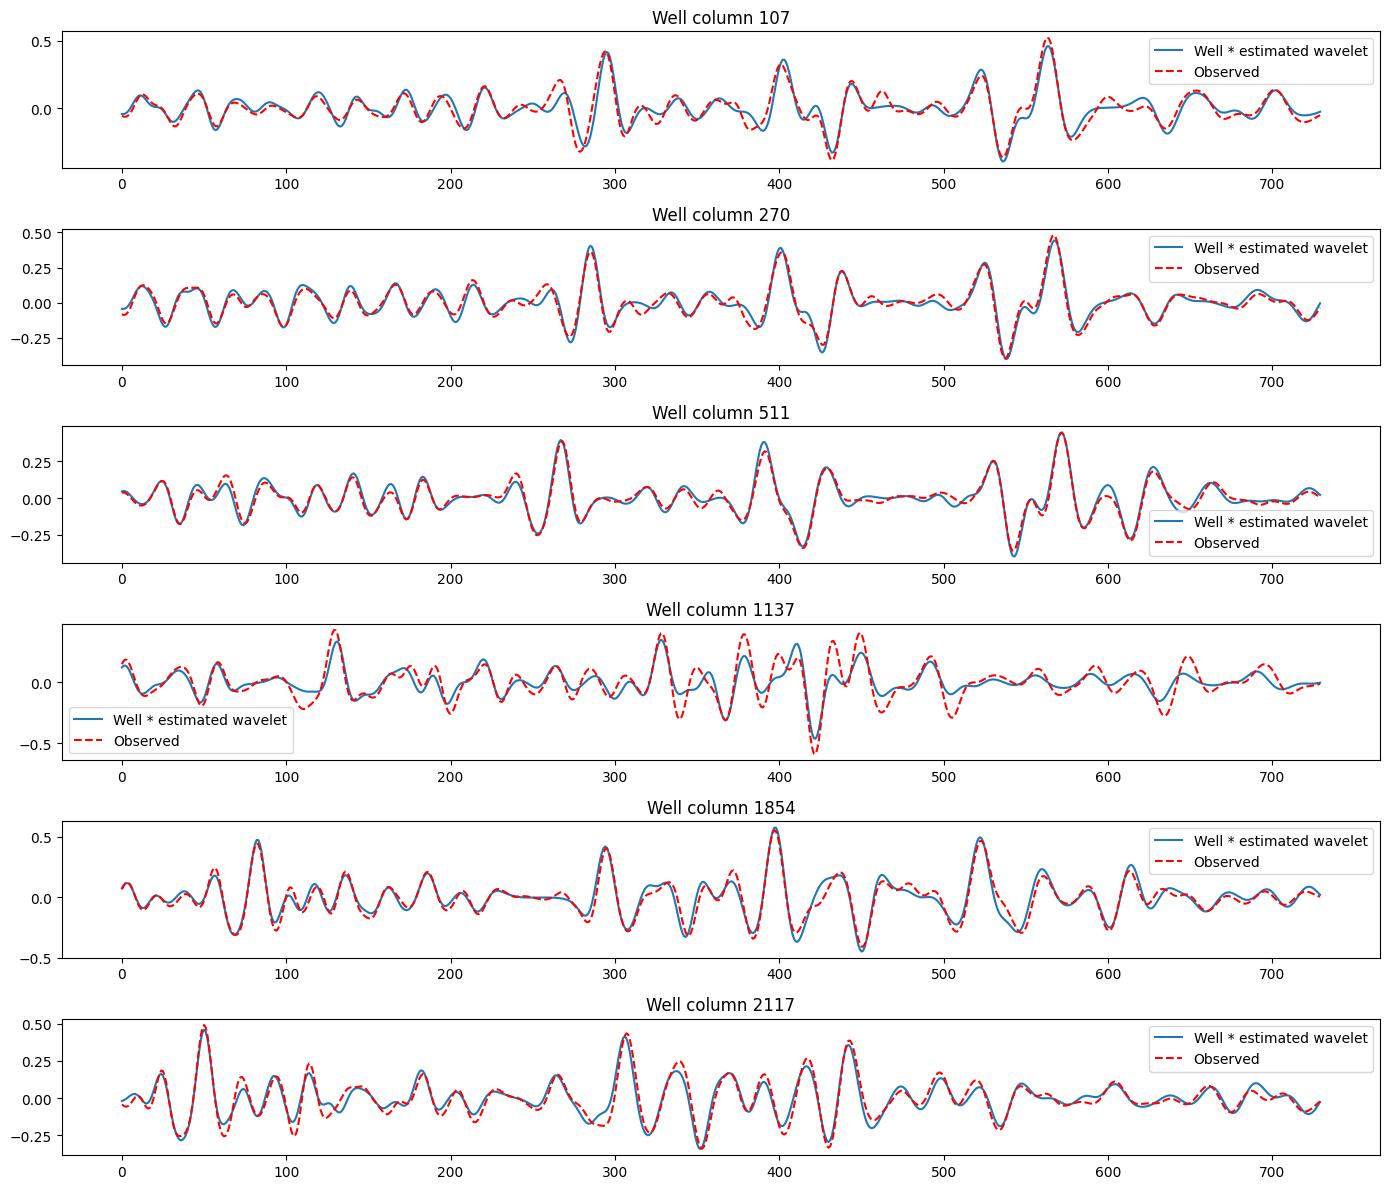

In [11]:
with torch.no_grad():
    seis_forward2 = wavelet_forward(
        wavelet_mat, data_well_slice.unsqueeze(0), window_new,
        seis_min, seis_max, imp_min, imp_max)
plt.figure(figsize=(14, max(3, 2 * len(dot))))
for j, trace in enumerate(dot):
    plt.subplot(len(dot), 1, j + 1)
    plt.plot(seis_forward2[0, 0, trace].cpu(), label="Well * estimated wavelet")
    plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
    plt.title(f"Well column {trace}")
    plt.legend()
plt.tight_layout()
plt.show()


## 9. Conditional Prior and Physical Update


In [12]:
def denoise(state, timestep):
    # Conditional clean-model prediction from v-prediction; DPS/DMPlug need input gradients, so do not apply no_grad globally.
    prior_counts["prior_evaluations"] += 1
    t = torch.tensor(timestep, device=device, dtype=torch.long)
    well_scale = min(1.0, denoise_well_end +
                     (denoise_well_start - denoise_well_end) * timestep / 1320)
    one = torch.ones((1, 1, 1, 1), device=device)
    down, mid = controlnet(
        state, t, encoder_hidden_states=None,
        controlnet_cond=[seismic_condition, well_condition],
        conditioning_scale=[one * denoise_seismic_scale, one * well_scale],
        guess_mode=False, return_dict=False)
    velocity = unet(
        state, t, None, down_block_additional_residuals=down,
        mid_block_additional_residual=mid).sample
    return (a[timestep] * state - b[timestep] * velocity).clamp(-1, 1)


def ddim_step(state, clean, timestep, next_t):
    # Preserve the framework-comparison deterministic DDIM expression instead of substituting the core notebook scheduler loop.
    if next_t < 0:
        return clean
    epsilon = (state - a[timestep] * clean) / b[timestep]
    return a[next_t] * clean + b[next_t] * epsilon


In [13]:
def wavelet_fn(image):
    operator_counts["seismic"] += 1
    return wavelet_forward(physical_wavelet, image, forward_window,
                           -amplitude_tensor, amplitude_tensor, imp_min, imp_max)


def background_fn(image):
    operator_counts["background"] += 1
    return background_filter(image)


def common_loss(image):
    data_loss = torch.linalg.vector_norm(wavelet_fn(image) - seismic_condition).square()
    background_loss = torch.linalg.vector_norm(background_fn(image) - initial_image).square()
    return seismic_loss_weight * data_loss + background_loss_weight * background_loss


def to_physical(image):
    return ((image.detach() * 0.5 + 0.5).clamp(0, 1)
            * imp_range + imp_min).cpu()


def evaluate_metrics(model):
    result = calc_metrics(model[0, 0], truth_image, metric_data_range)
    with torch.no_grad():
        normalized = (model.to(device) - imp_min) / imp_range * 2 - 1
        residual = wavelet_fn(normalized) - seismic_condition
        seismic_rmse = float(residual.square().mean().sqrt().cpu())
    result["seismic_RMSE_normalized"] = seismic_rmse
    result["seismic_RMSE_raw"] = seismic_rmse * seismic_amplitude
    return result


def adam(parameter, rate):
    return torch.optim.Adam([parameter], lr=float(rate), betas=(0.9, 0.999),
                            eps=1e-8, weight_decay=0, amsgrad=False)


def data_fitting(reference, learning_rate, coupling_weight):
    # Start each round from its current prediction and recreate Adam.
    candidate = reference.clone().requires_grad_(True)
    optimizer = adam(candidate, learning_rate)
    block_losses = []
    for _ in range(num_iterations):
        optimizer.zero_grad(set_to_none=True)
        loss = common_loss(candidate) + coupling_weight * torch.linalg.vector_norm(candidate - reference).square()
        loss.backward()
        optimizer.step()
        block_losses.append(float(loss.detach()))
    return candidate.detach().clamp(-1, 1), block_losses


## 10. Inversion Parameters


In [14]:
num_runs = 1
seed_start = 42
plot_seed = seed_start
epochs = 45
N_rev = 1
num_iterations = 2
plot_interval = max(1, epochs // 5)

forward_wavelet_weight = 1.0
initial_weight = 1.0
c_D = 0.0035
zeta = 0.3
well_scale_start, well_scale_end = 4.0, 0.2
seismic_control_scale = 1.0
background_implementation = "fft"
# Backward activations for full-size Marmousi can be offloaded to host memory while preserving FP32 gradients and updates.
cpu_saved_tensor_offload = False
lr_scheduler = np.linspace(0.0001, 0.001, epochs)
timesteps = (np.linspace(1320, 0, epochs).round().astype(np.int64)
             if epochs > 1 else np.array([1320], dtype=np.int64))
if num_runs < 1 or epochs < 1:
    raise ValueError("num_runs and epochs must both be at least 1.")
if N_rev != 1:
    raise ValueError("This method uses one conditional clean-model prediction per round. epochs sets the iteration budget.")


## 11. Inversion Process


Seed 42:   0%|          | 0/45 [00:00<?, ?it/s]

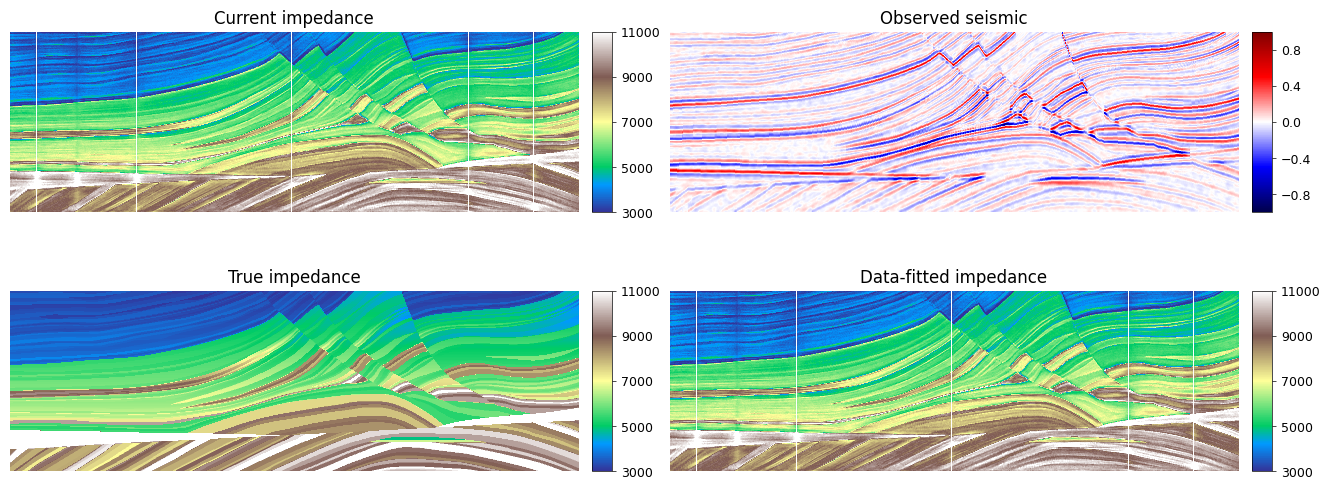

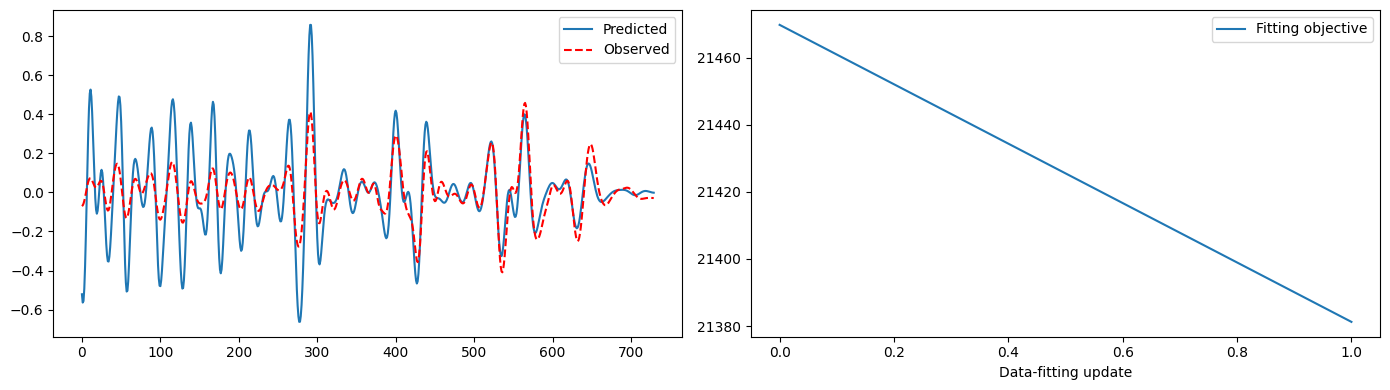

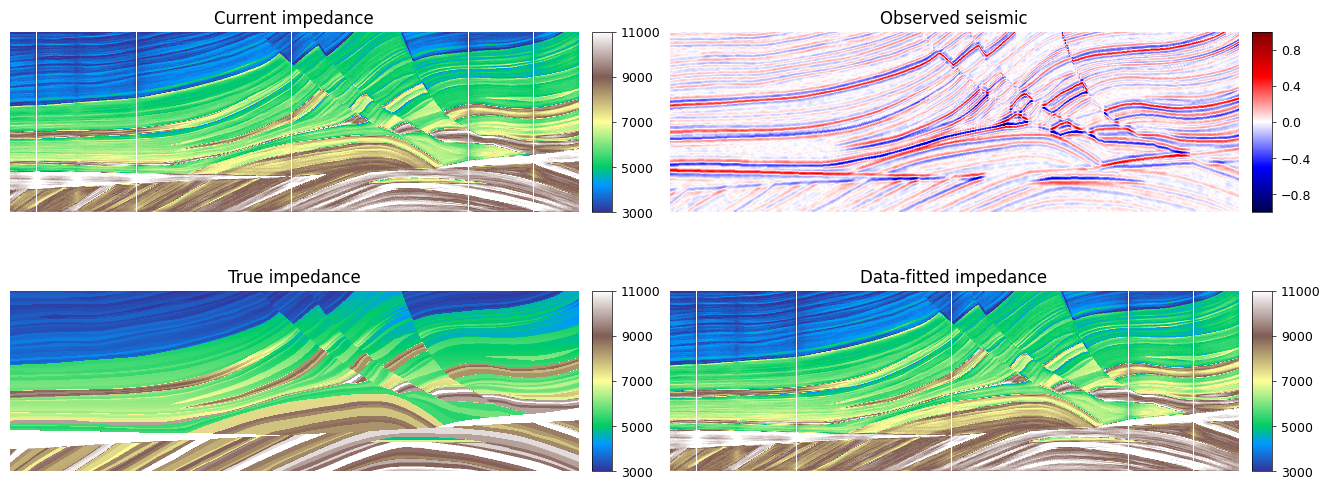

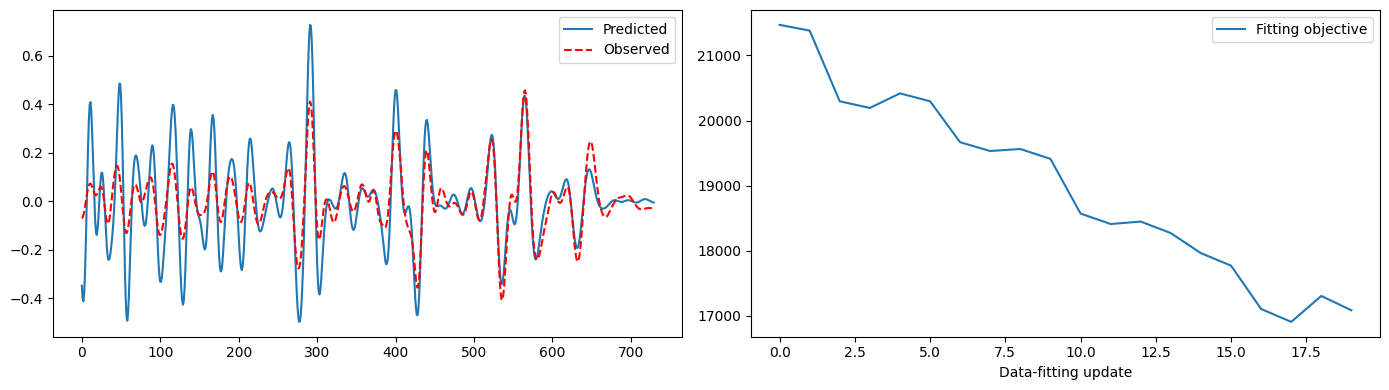

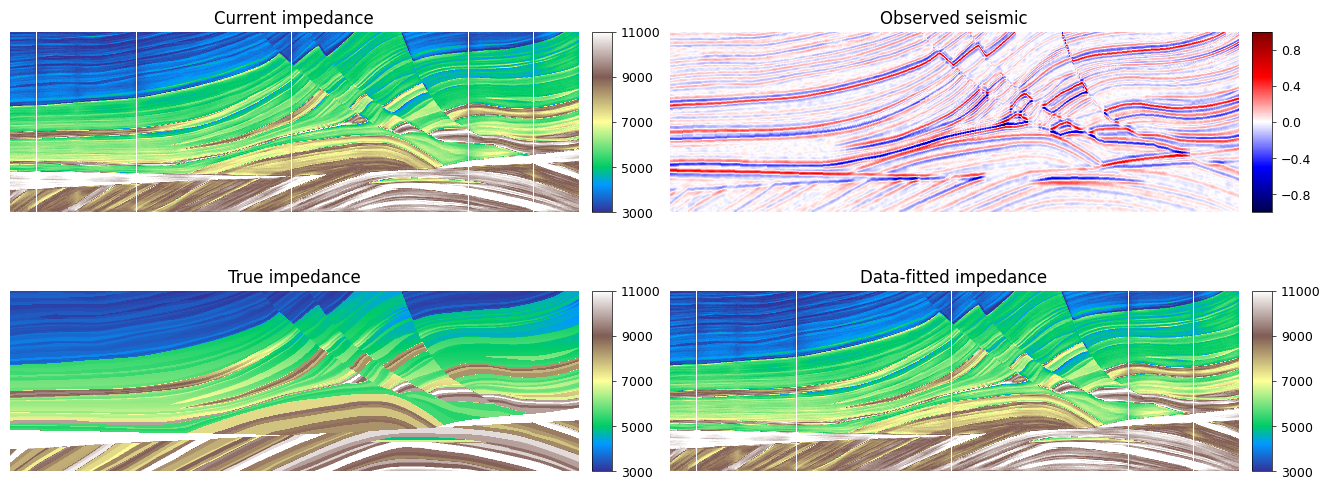

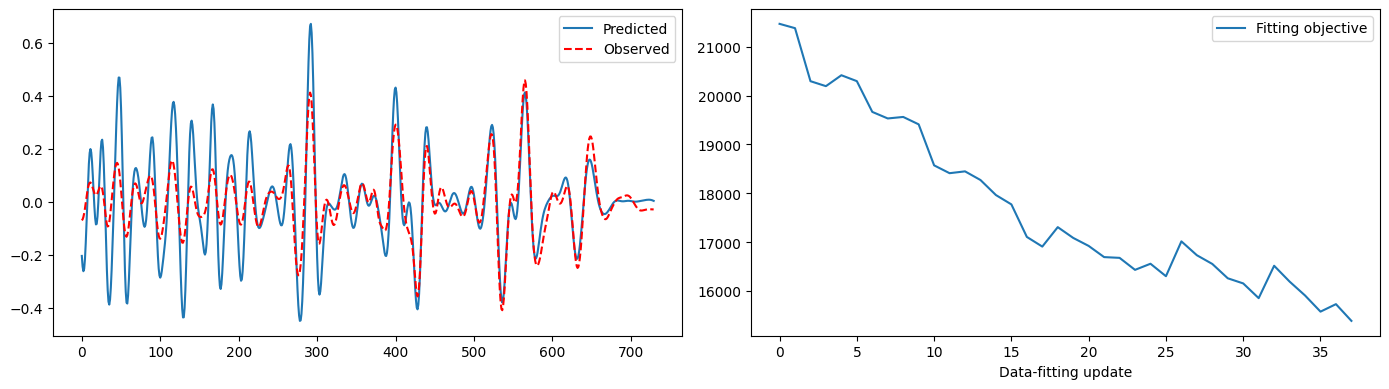

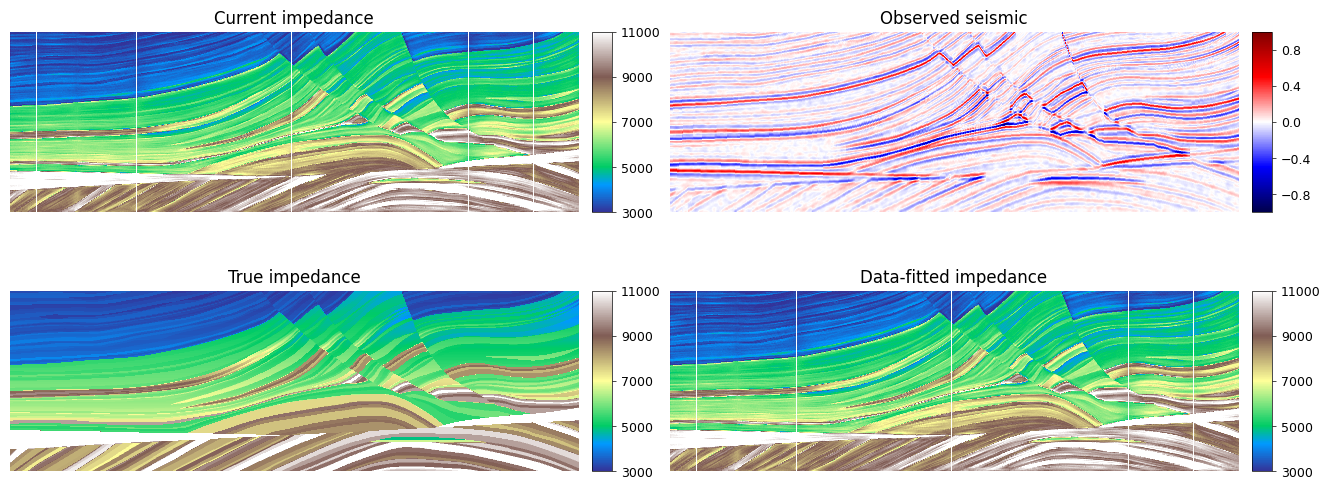

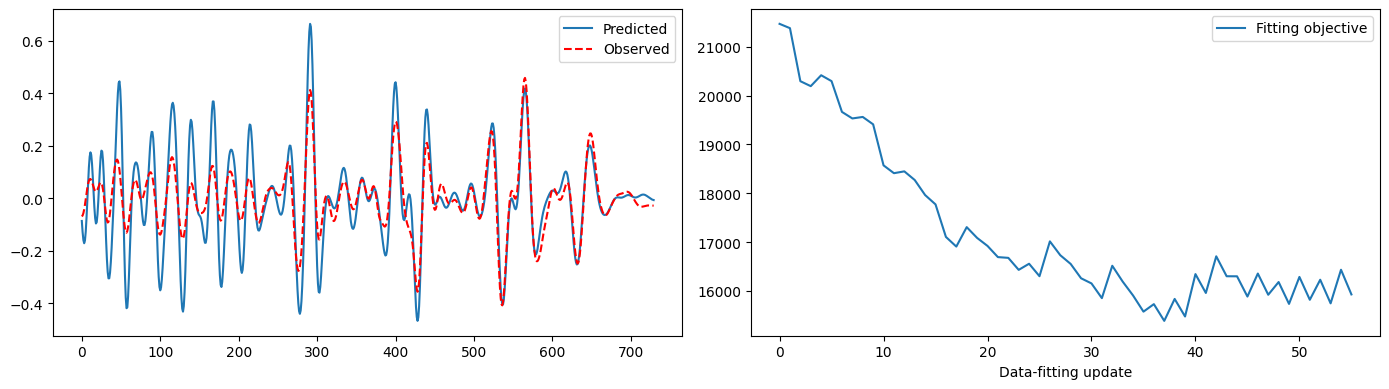

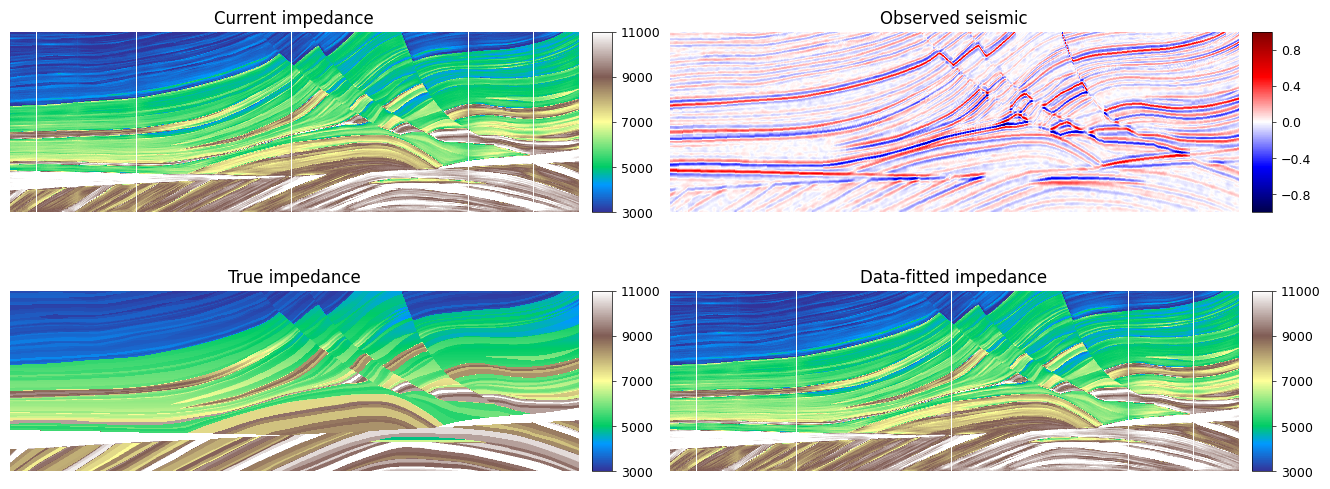

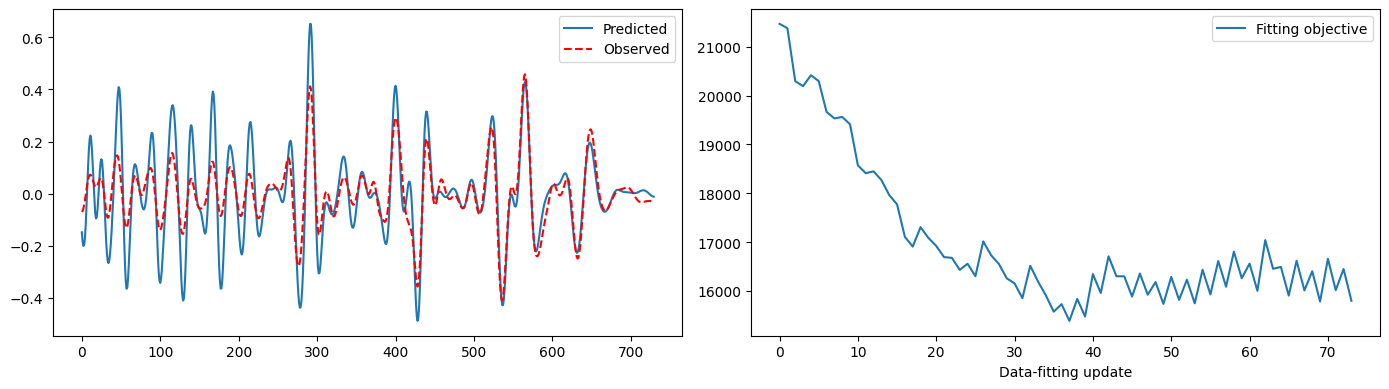

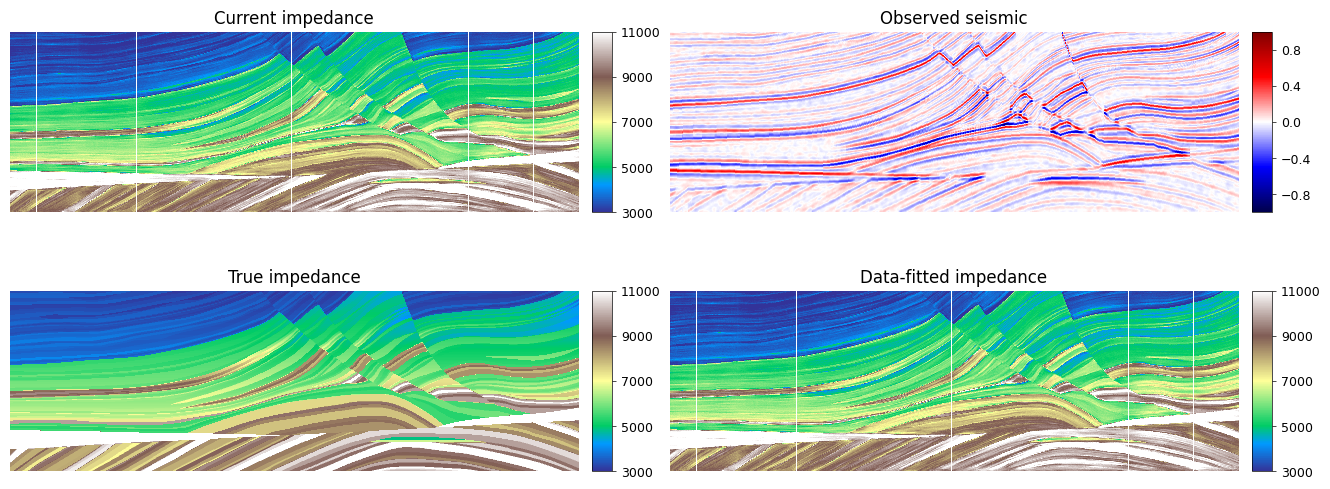

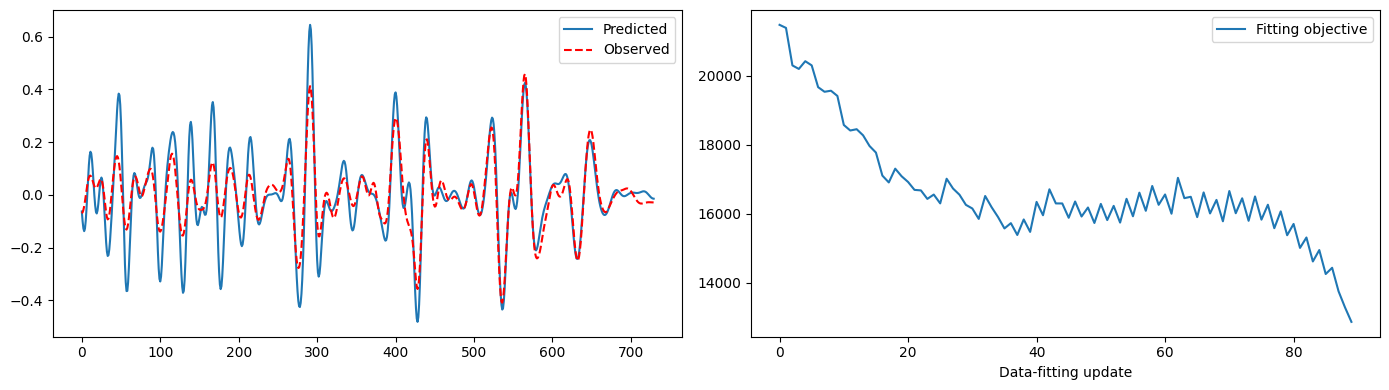

Seed: 42 | Metrics: {'RMSE': 610.1270751953125, 'PSNR': 26.993903468644373, 'SSIM': 0.8682079911231995, 'MAE': 421.0727233886719, 'CorrCoef': 0.9702803694188292, 'seismic_RMSE_normalized': 0.07658544182777405, 'seismic_RMSE_raw': 0.04347061893310311}


In [15]:
# Preserve the original Prior construction order for alpha/a/b; parameter values come from cell 24.
denoise_well_start, denoise_well_end = well_scale_start, well_scale_end
denoise_seismic_scale = seismic_control_scale
alpha_scheduler = DDIMScheduler.from_config(scheduler.config)
if alpha_scheduler.config.num_train_timesteps != 1500 or alpha_scheduler.config.prediction_type != "v_prediction":
    raise ValueError("The checkpoint timesteps or prediction type differ from those used in the paper.")
alpha = alpha_scheduler.alphas_cumprod.to(device)
a, b = alpha.sqrt(), (1 - alpha).sqrt()
prior_counts = {"prior_evaluations": 0}
# Use the wavelet produced in cell 16, preserving the original detach/float/device conversion order.
physical_wavelet = wavelet_mat.detach().float().to(device)
background_filter = prepare_background(kernel_data, implementation=background_implementation)
operator_counts = {"seismic": 0, "background": 0}
seismic_loss_weight = forward_wavelet_weight
background_loss_weight = initial_weight
assert torch.equal(seismic_condition, cond_image)
assert torch.equal(initial_image, smoothed_norm)
results = []
run_records = []
for iter in range(num_runs):
    seed = seed_start + iter
    torch.manual_seed(seed)
    np.random.seed(seed)
    generator = torch.Generator(device=device).manual_seed(seed)
    initial_noise = torch.randn(image_shape, generator=generator, device=device)
    state = a[1320] * initial_image.clone() + b[1320] * initial_noise
    image = initial_image.clone()
    image_fit = image.clone()
    prior_counts = {"prior_evaluations": 0}
    operator_counts["seismic"] = operator_counts["background"] = 0
    loss_trace = []
    updates = 0
    started = time.perf_counter()
    storage = (torch.autograd.graph.save_on_cpu(pin_memory=True)
               if cpu_saved_tensor_offload and device.type == "cuda" else nullcontext())
    with storage:
        for i in tqdm(range(epochs), total=epochs, desc=f"Seed {seed}"):
            timestep = int(timesteps[i])
            with torch.no_grad():
                reference = denoise(state, timestep).detach()
            q_t = (1 - alpha[timestep]) / alpha[timestep]
            image_fit, block_losses = data_fitting(reference, lr_scheduler[i], c_D / q_t)
            loss_trace.extend(block_losses)
            updates += num_iterations
            image = image_fit
            if i + 1 < len(timesteps):
                next_t = int(timesteps[i + 1])
                implied_noise = (state - a[timestep] * image_fit) / b[timestep]
                fresh_noise = torch.randn(state.shape, generator=generator, device=device)
                state = a[next_t] * image_fit + b[next_t] * (
                    np.sqrt(1 - zeta) * implied_noise + np.sqrt(zeta) * fresh_noise)

            if seed == plot_seed and plot_interval and (i % plot_interval == 0 or i == epochs - 1):
                with torch.no_grad():
                    shown_model = to_physical(image)
                    shown_fit = to_physical(image_fit)
                    seis_forward = wavelet_forward(
                        wavelet_mat, image.detach(), window_new,
                        -amplitude_tensor, amplitude_tensor, imp_min, imp_max)
                plt.figure(figsize=section_figure_size(raw_image.shape[-2:], rows=2, cols=2, dataset=plot_options["dataset"]))
                for panel, array, title, colors, lo, hi in [
                    (1, shown_model[0, 0], "Current impedance", cmap, plot_min, plot_max),
                    (2, cond_image[0, 0].cpu(), "Observed seismic", cmap2, -1, 1),
                    (3, raw_image_denorm[0].cpu(), "True impedance", cmap, plot_min, plot_max),
                    (4, shown_fit[0, 0], "Data-fitted impedance", cmap, plot_min, plot_max)]:
                    plt.subplot(2, 2, panel)
                    plt.imshow(array.cpu().T, cmap=colors, vmin=lo, vmax=hi, aspect=aspect)
                    paper_section(plt.gca(), plt.gci(), impedance=colors is cmap,
                                  show_wells=title != "True impedance", **plot_options)
                    plt.title(title)
                    add_colorbar(plt.gcf(), plt.gci(), plt.gca())
                plt.tight_layout()
                plt.show()

                plt.figure(figsize=(14, 4))
                plt.subplot(121)
                trace = min(200, seis.shape[-2] - 1)
                plt.plot(seis_forward[0, 0, trace].cpu(), label="Predicted")
                plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
                plt.legend()
                plt.subplot(122)
                if loss_trace:
                    plt.plot(loss_trace, label="Fitting objective")
                    plt.legend()
                plt.xlabel("Data-fitting update")
                plt.tight_layout()
                plt.show()
    expected_updates = num_iterations * epochs
    expected_denoising = epochs * 1
    assert updates == expected_updates
    assert prior_counts["prior_evaluations"] == expected_denoising
    assert operator_counts["seismic"] == operator_counts["background"] == expected_updates
    physical = to_physical(image)
    if not torch.isfinite(physical).all():
        raise FloatingPointError("The inverted model contains nonfinite values.")
    metrics = evaluate_metrics(physical)
    results.append(physical)
    record = dict(seed=seed, metrics=metrics, loss_trace=loss_trace,
                  elapsed_seconds=time.perf_counter() - started)
    run_records.append(record)
    np.save(output_dir / f"seed_{seed}.npy", physical[0, 0].numpy())
    (output_dir / f"seed_{seed}.json").write_text(
        json.dumps(record, indent=2) + "\n", encoding="utf-8")
    print("Seed:", seed, "| Metrics:", metrics)


## 12. Ensemble Evaluation, Plotting, and Saving


,seed,RMSE,PSNR,SSIM,MAE,CorrCoef,seismic_RMSE_normalized,seismic_RMSE_raw
0,42,610.127075,26.993903,0.868208,421.072723,0.97028,0.076585,0.043471


Mean model: {'RMSE': 610.1270751953125, 'PSNR': 26.993903468644373, 'SSIM': 0.8682079911231995, 'MAE': 421.0727233886719, 'CorrCoef': 0.9702803694188292}
Mean individual-run metrics: {'RMSE': 610.1270751953125, 'MAE': 421.0727233886719, 'SSIM': 0.8682079911231995, 'CorrCoef': 0.9702803694188292}


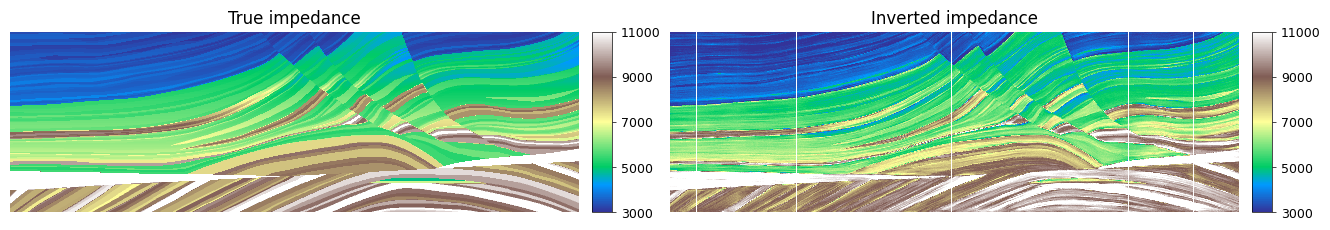

In [16]:
filt_results = torch.cat(results, dim=0)
image = filt_results.mean(0, keepdim=True)
image_std = filt_results.std(0, correction=1) if len(results) > 1 else torch.zeros_like(filt_results[0])
evaluation = calc_metrics(image[0, 0], raw_image_denorm[0].cpu(), imp_max - imp_min)
table = pd.DataFrame([dict(seed=r["seed"], **r["metrics"]) for r in run_records])
display(table)
independent_mean = {key: float(table[key].mean()) for key in ["RMSE", "MAE", "SSIM", "CorrCoef"]}
print("Mean model:", evaluation)
print("Mean individual-run metrics:", independent_mean)
summary = dict(ensemble=evaluation, independent_mean=independent_mean,
               seeds=[r["seed"] for r in run_records])
(output_dir / "metrics_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
np.save(output_dir / "ensemble_mean.npy", image[0, 0].numpy())
np.save(output_dir / "ensemble_std.npy", image_std[0].numpy())
table.to_csv(output_dir / "metrics_per_run.csv", index=False)

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(image[0, 0].T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Inverted impedance" if num_runs == 1 else "Mean inversion")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.savefig(output_dir / "inversion_result.png", dpi=160, bbox_inches="tight")
plt.show()
